In [20]:
from collections import Counter
from pathlib import Path

import pandas as pd
from rdflib import Graph, Literal, Namespace, URIRef
from rdflib.namespace import OWL, RDF, RDFS, SKOS

BASE_DIR = Path.cwd().parent
DATA_DIR = BASE_DIR / "data"

wittgensteiniana_path = DATA_DIR / "wittgensteiniana_final.ttl"
wab_path = DATA_DIR / "wab_tractatus_subgraph.ttl"

wittgensteiniana = Graph()
wittgensteiniana.parse(str(wittgensteiniana_path), format="turtle")

wab = Graph()
wab.parse(str(wab_path), format="turtle")

print("Wittgensteiniana loaded:", len(wittgensteiniana))
print("WAB loaded:", len(wab))

Wittgensteiniana loaded: 15567
WAB loaded: 27253


In [6]:
graphs = {
    "Wittgensteiniana": wittgensteiniana,
    "WAB": wab
}

for name, graph in graphs.items():
    print("\n")
    print(name)

    types = Counter(
        str(obj)
        for _, _, obj in graph.triples((None, RDF.type, None))
    )

    print("\nRDF types:")
    for rdf_type, count in types.most_common():
        print(f"{count:6} | {rdf_type}")

    print("\nTotal triples:", len(graph))



Wittgensteiniana

RDF types:
  1578 | http://example.org/wittgensteiniana/TextFragment
  1578 | https://schema.org/CreativeWork
   526 | http://example.org/wittgensteiniana/Thesis
   526 | https://schema.org/Chapter
   182 | https://schema.org/DefinedTerm
     8 | http://www.w3.org/2002/07/owl#Class
     7 | http://www.w3.org/2002/07/owl#ObjectProperty
     6 | http://www.w3.org/2002/07/owl#DatatypeProperty
     4 | http://example.org/wittgensteiniana/Author
     3 | https://schema.org/Book
     1 | https://schema.org/DefinedTermSet

Total triples: 15567


WAB

RDF types:
  1619 | http://purl.org/wittgensteinsource/ont/TS
  1616 | http://purl.org/wittgensteinsource/ont/Bemerkung
   531 | http://purl.org/wittgensteinsource/ont/Part
    21 | http://purl.org/wittgensteinsource/ont/scholar/0.1/Person
    13 | http://purl.org/wittgensteinsource/ont/WittgensteinExternalSource
    10 | http://www.w3.org/2002/07/owl#ObjectProperty
     6 | http://purl.org/wittgensteinsource/ont/scholar/0.1/T

In [10]:
SCHEMA = Namespace("https://schema.org/")
WAB_NS = Namespace("http://purl.org/wittgensteinsource/ont/")

label_properties = {
    "rdfs:label": RDFS.label,
    "skos:prefLabel": SKOS.prefLabel,
    "skos:altLabel": SKOS.altLabel,
    "schema:name": SCHEMA.name,
}

for name, graph in graphs.items():
    print("\n")
    print(name)

    for property_name, property_uri in label_properties.items():
        values = list(graph.triples((None, property_uri, None)))
        print(f"{property_name}: {len(values)}")




Wittgensteiniana
rdfs:label: 4
skos:prefLabel: 0
skos:altLabel: 0
schema:name: 712


WAB
rdfs:label: 2210
skos:prefLabel: 0
skos:altLabel: 0
schema:name: 0


In [11]:
for name, graph in graphs.items():
    print("\n")
    print(name)

    predicates = Counter(
        str(predicate)
        for _, predicate, _ in graph
        if predicate != RDF.type
    )

    print("\nMost frequent predicates:")

    for predicate, count in predicates.most_common(30):
        print(f"{count:6} | {predicate}")

    print("\nObject property declarations:")

    for prop in sorted(
        graph.subjects(RDF.type, OWL.ObjectProperty),
        key=str
    ):
        domains = list(graph.objects(prop, RDFS.domain))
        ranges = list(graph.objects(prop, RDFS.range))

        print(f"\nProperty: {prop}")
        print("Domain:", domains if domains else "Not specified")
        print("Range:", ranges if ranges else "Not specified")



Wittgensteiniana

Most frequent predicates:
  2104 | https://schema.org/isPartOf
  1581 | https://schema.org/inLanguage
  1578 | http://example.org/wittgensteiniana/hasTextFragment
  1578 | https://schema.org/exampleOfWork
  1578 | https://schema.org/text
  1095 | https://schema.org/mentions
   712 | https://schema.org/name
   526 | https://schema.org/position
   182 | https://schema.org/inDefinedTermSet
   177 | https://schema.org/description
    13 | http://www.w3.org/2000/01/rdf-schema#range
    11 | http://www.w3.org/2000/01/rdf-schema#domain
     4 | http://example.org/wittgensteiniana/hasAuthor
     4 | http://www.w3.org/2000/01/rdf-schema#label
     3 | https://schema.org/datePublished
     2 | https://schema.org/translationOfWork

Object property declarations:

Property: http://example.org/wittgensteiniana/hasAuthor
Domain: [rdflib.term.URIRef('https://schema.org/Book')]
Range: [rdflib.term.URIRef('http://example.org/wittgensteiniana/Author')]

Property: http://example.org/wi

In [16]:
from rdflib.namespace import RDF, RDFS

def get_resource_labels(graph, resource):
    labels = []

    for predicate, obj in graph.predicate_objects(resource):
        predicate_name = str(predicate)

        if predicate_name in [
            "http://www.w3.org/2000/01/rdf-schema#label",
            "https://schema.org/name"
        ]:
            labels.append(str(obj))

    return labels


types_to_inspect = {
    "Wittgensteiniana": [
        "http://example.org/wittgensteiniana/Thesis",
        "http://example.org/wittgensteiniana/TextFragment",
        "http://example.org/wittgensteiniana/Author",
        "https://schema.org/Book"
    ],
    "WAB": [
        "http://purl.org/wittgensteinsource/ont/Bemerkung",
        "http://purl.org/wittgensteinsource/ont/TS",
        "http://purl.org/wittgensteinsource/ont/Part",
        "http://purl.org/wittgensteinsource/ont/Person",
        "http://purl.org/wittgensteinsource/ont/Werk"
    ]
}

for graph_name, graph in graphs.items():
    print("\n")
    print(graph_name)

    for class_uri in types_to_inspect[graph_name]:
        class_uri = URIRef(class_uri)

        instances = sorted(
            graph.subjects(RDF.type, class_uri),
            key=str
        )

        print(f"\nClass: {class_uri.split('/')[-1]}")
        print(f"Number of instances: {len(instances)}")

        for instance in instances[:5]:
            labels = get_resource_labels(graph, instance)

            print("  URI:", instance)
            print("  Labels:", labels if labels else "No label")



Wittgensteiniana

Class: Thesis
Number of instances: 526
  URI: http://wittgensteiniana.michelepasin.org/id/unit/1000
  Labels: ['6.2341']
  URI: http://wittgensteiniana.michelepasin.org/id/unit/1001
  Labels: ['6.24']
  URI: http://wittgensteiniana.michelepasin.org/id/unit/1002
  Labels: ['6.241']
  URI: http://wittgensteiniana.michelepasin.org/id/unit/1003
  Labels: ['6.3']
  URI: http://wittgensteiniana.michelepasin.org/id/unit/1004
  Labels: ['6.31']

Class: TextFragment
Number of instances: 1578
  URI: http://wittgensteiniana.michelepasin.org/id/fragment/1000-german
  Labels: No label
  URI: http://wittgensteiniana.michelepasin.org/id/fragment/1000-ogden
  Labels: No label
  URI: http://wittgensteiniana.michelepasin.org/id/fragment/1000-pears
  Labels: No label
  URI: http://wittgensteiniana.michelepasin.org/id/fragment/1001-german
  Labels: No label
  URI: http://wittgensteiniana.michelepasin.org/id/fragment/1001-ogden
  Labels: No label

Class: Author
Number of instances: 4
  

In [14]:
print("Wittgensteiniana triples:", len(wittgensteiniana))
print("WAB triples:", len(wab))

print("\nAll classes containing 'Person' in WAB:")

person_classes = sorted(
    {
        obj
        for _, _, obj in wab.triples((None, RDF.type, None))
        if "Person" in str(obj)
    },
    key=str
)

for cls in person_classes:
    instances = list(wab.subjects(RDF.type, cls))
    print(f"\nClass URI: {cls}")
    print(f"Instances: {len(instances)}")

    for person in instances[:25]:
        print(" ", person)
        

Wittgensteiniana triples: 15567
WAB triples: 27225

All classes containing 'Person' in WAB:

Class URI: http://purl.org/wittgensteinsource/ont/scholar/0.1/Person
Instances: 21
  http://purl.org/wittgensteinsource/ont/instances/C%C3%A4sar__Gaius_Julius
  http://purl.org/wittgensteinsource/ont/instances/Darwin__Charles
  http://purl.org/wittgensteinsource/ont/instances/Engelmann__Paul
  http://purl.org/wittgensteinsource/ont/instances/Mauthner__Fritz
  http://purl.org/wittgensteinsource/ont/instances/Newton__Isaac
  http://purl.org/wittgensteinsource/ont/instances/Pinsent__David_Hume
  http://purl.org/wittgensteinsource/ont/instances/Sokrates
  http://purl.org/wittgensteinsource/ont/instances/Wanicek__Aloisia
  http://purl.org/wittgensteinsource/ont/instances/Ernst__Paul
  http://purl.org/wittgensteinsource/ont/instances/Grimm__Jacob%3B_Grimm__Wilhelm
  http://purl.org/wittgensteinsource/ont/instances/K%C3%BCrnberger__Ferdinand
  http://purl.org/wittgensteinsource/ont/instances/Kant__Imm

In [15]:
WAB_HAS_AUTHOR = URIRef(
    "http://purl.org/wittgensteinsource/ont/scholar/0.1/hasAuthor"
)

WAB_PERSON = URIRef(
    "http://purl.org/wittgensteinsource/ont/scholar/0.1/Person"
)

wab_persons = sorted(
    wab.subjects(RDF.type, WAB_PERSON),
    key=str
)

print("WAB persons:", len(wab_persons))

for person in wab_persons:
    labels = list(wab.objects(person, RDFS.label))

    author_of = list(wab.subjects(WAB_HAS_AUTHOR, person))

    print("\nPerson:", labels if labels else person)
    print("URI:", person)
    print("Linked as author:", len(author_of))

    for resource in author_of[:5]:
        resource_labels = list(wab.objects(resource, RDFS.label))
        print("  Author of:", resource_labels if resource_labels else resource)

WAB persons: 21

Person: [rdflib.term.Literal('Cäsar, Gaius Julius')]
URI: http://purl.org/wittgensteinsource/ont/instances/C%C3%A4sar__Gaius_Julius
Linked as author: 0

Person: [rdflib.term.Literal('Darwin, Charles')]
URI: http://purl.org/wittgensteinsource/ont/instances/Darwin__Charles
Linked as author: 0

Person: [rdflib.term.Literal('Engelmann, Paul')]
URI: http://purl.org/wittgensteinsource/ont/instances/Engelmann__Paul
Linked as author: 0

Person: [rdflib.term.Literal('Ernst, Paul')]
URI: http://purl.org/wittgensteinsource/ont/instances/Ernst__Paul
Linked as author: 0

Person: [rdflib.term.Literal('Frege, Gottlob')]
URI: http://purl.org/wittgensteinsource/ont/instances/Frege__Gottlob
Linked as author: 0

Person: [rdflib.term.Literal('Grimm, Jacob; Grimm, Wilhelm')]
URI: http://purl.org/wittgensteinsource/ont/instances/Grimm__Jacob%3B_Grimm__Wilhelm
Linked as author: 0

Person: [rdflib.term.Literal('Hertz, Heinrich')]
URI: http://purl.org/wittgensteinsource/ont/instances/Hertz__He

In [18]:
for person in wab_persons:
    label = next(wab.objects(person, RDFS.label), person)

    print("\n")
    print("Person:", label)

    print("Outgoing relations:")
    for predicate, obj in wab.predicate_objects(person):
        print(f"  {predicate.split('/')[-1]} -> {obj}")

    print("Incoming relations:")
    for subject, predicate in wab.subject_predicates(person):
        print(f"  {predicate.split('/')[-1]} <- {subject}")



Person: Cäsar, Gaius Julius
Outgoing relations:
  22-rdf-syntax-ns#type -> http://purl.org/wittgensteinsource/ont/scholar/0.1/Person
  rdf-schema#label -> Cäsar, Gaius Julius
  isReferredToIn -> http://wittgensteinsource.org/Ts-202%2C24r%5B8%5Det25r%5B1%5D_d
  isReferredToIn -> http://wittgensteinsource.org/Ts-203%2C27r%5B7%5D_d
  isReferredToIn -> http://wittgensteinsource.org/Ts-204%2C24r%5B8%5Det25r%5B1%5D_d
Incoming relations:


Person: Darwin, Charles
Outgoing relations:
  22-rdf-syntax-ns#type -> http://purl.org/wittgensteinsource/ont/scholar/0.1/Person
  rdf-schema#label -> Darwin, Charles
  isReferredToIn -> http://wittgensteinsource.org/Ts-202%2C15av%5B1%5D-relocated_d
  isReferredToIn -> http://wittgensteinsource.org/Ts-202%2C15r%5B7%5Det15av%5B1%5Det16r%5B1%5D_d
  isReferredToIn -> http://wittgensteinsource.org/Ts-204%2C16r%5B3%5D_d
Incoming relations:


Person: Engelmann, Paul
Outgoing relations:
  22-rdf-syntax-ns#type -> http://purl.org/wittgensteinsource/ont/scholar/0.

In [23]:
for name, graph in graphs.items():
    rdf_types = {
        obj
        for _, predicate, obj in graph
        if predicate == RDF.type
    }

    excluded_types = {
        OWL.Class,
        RDFS.Class,
        OWL.ObjectProperty,
        OWL.DatatypeProperty,
        OWL.AnnotationProperty,
        RDF.Property,
        OWL.Ontology,
        OWL.NamedIndividual
    }

    candidate_classes = sorted(
        rdf_types - excluded_types,
        key=str
    )

    print(f"\n{name}")
    print("Number of candidate classes:", len(candidate_classes))

    for cls in candidate_classes:
        instances = set(graph.subjects(RDF.type, cls))
        print(f"{len(instances):5} | {cls}")


Wittgensteiniana
Number of candidate classes: 8
    4 | http://example.org/wittgensteiniana/Author
 1578 | http://example.org/wittgensteiniana/TextFragment
  526 | http://example.org/wittgensteiniana/Thesis
    3 | https://schema.org/Book
  526 | https://schema.org/Chapter
 1578 | https://schema.org/CreativeWork
  182 | https://schema.org/DefinedTerm
    1 | https://schema.org/DefinedTermSet

WAB
Number of candidate classes: 9
 1616 | http://purl.org/wittgensteinsource/ont/Bemerkung
  531 | http://purl.org/wittgensteinsource/ont/Part
 1619 | http://purl.org/wittgensteinsource/ont/TS
    1 | http://purl.org/wittgensteinsource/ont/Werk
   13 | http://purl.org/wittgensteinsource/ont/WittgensteinExternalSource
    2 | http://purl.org/wittgensteinsource/ont/scholar/0.1/Date
    1 | http://purl.org/wittgensteinsource/ont/scholar/0.1/Language
   21 | http://purl.org/wittgensteinsource/ont/scholar/0.1/Person
    6 | http://purl.org/wittgensteinsource/ont/scholar/0.1/TextSubGenre


In [27]:
def get_candidate_classes(graph):
    excluded_types = {
        OWL.Class,
        RDFS.Class,
        OWL.ObjectProperty,
        OWL.DatatypeProperty,
        OWL.AnnotationProperty,
        RDF.Property,
        OWL.Ontology,
        OWL.NamedIndividual
    }

    rdf_types = {
        obj
        for _, _, obj in graph.triples((None, RDF.type, None))
    }

    return sorted(rdf_types - excluded_types, key=str)


def get_resource_labels(graph, resource):
    label_properties = [
        RDFS.label,
        SKOS.prefLabel,
        SKOS.altLabel,
        SCHEMA.name
    ]

    labels = []

    for prop in label_properties:
        labels.extend(
            str(value)
            for value in graph.objects(resource, prop)
        )

    return list(dict.fromkeys(labels))


def get_class_statistics(graph, ontology_name):
    rows = []

    declared_classes = set(graph.subjects(RDF.type, OWL.Class))
    declared_classes.update(graph.subjects(RDF.type, RDFS.Class))

    for cls in get_candidate_classes(graph):
        instances = set(graph.subjects(RDF.type, cls))
        labels = get_resource_labels(graph, cls)

        rows.append({
            "Ontology": ontology_name,
            "Class URI": str(cls),
            "Local name": str(cls).split("/")[-1].split("#")[-1],
            "Labels": "; ".join(labels) if labels else None,
            "Number of instances": len(instances),
            "Explicitly declared": cls in declared_classes
        })

    return rows


class_rows = []

class_rows.extend(
    get_class_statistics(wittgensteiniana, "Wittgensteiniana")
)

class_rows.extend(
    get_class_statistics(wab, "WAB")
)

classes_df = pd.DataFrame(class_rows)

classes_df

,Ontology,Class URI,Local name,Labels,Number of instances,Explicitly declared
0,Wittgensteiniana,http://example.org/wittgensteiniana/Author,Author,NaN,4,True
1,Wittgensteiniana,http://example.org/wittgensteiniana/TextFragment,TextFragment,NaN,1578,True
2,Wittgensteiniana,http://example.org/wittgensteiniana/Thesis,Thesis,NaN,526,True
3,Wittgensteiniana,https://schema.org/Book,Book,NaN,3,True
4,Wittgensteiniana,https://schema.org/Chapter,Chapter,NaN,526,True
5,Wittgensteiniana,https://schema.org/CreativeWork,CreativeWork,NaN,1578,True
6,Wittgensteiniana,https://schema.org/DefinedTerm,DefinedTerm,NaN,182,True
7,Wittgensteiniana,https://schema.org/DefinedTermSet,DefinedTermSet,NaN,1,True
8,WAB,http://purl.org/wittgensteinsource/ont/Bemerkung,Bemerkung,Nachlass Bemerkung,1616,True
9,WAB,http://purl.org/wittgensteinsource/ont/Part,Part,Part,531,True


In [28]:
classes_comparison = classes_df.pivot_table(
    index="Local name",
    columns="Ontology",
    values="Number of instances",
    aggfunc="first"
).fillna(0).astype(int)

classes_comparison

Ontology,WAB,Wittgensteiniana
Local name,,
Author,0,4
Bemerkung,1616,0
Book,0,3
Chapter,0,526
CreativeWork,0,1578
Date,2,0
DefinedTerm,0,182
DefinedTermSet,0,1
Language,1,0


In [30]:
from difflib import SequenceMatcher
import re

def normalize_name(value):
    value = str(value)
    value = re.sub(r"([a-z])([A-Z])", r"\1 \2", value)
    value = re.sub(r"[_\-]", " ", value)
    return " ".join(value.lower().split())


classes_df["Comparison name"] = classes_df.apply(
    lambda row: normalize_name(
        row["Labels"] if pd.notna(row["Labels"]) else row["Local name"]
    ),
    axis=1
)

classes_df[[
    "Ontology",
    "Local name",
    "Labels",
    "Comparison name"
]]

,Ontology,Local name,Labels,Comparison name
0,Wittgensteiniana,Author,NaN,author
1,Wittgensteiniana,TextFragment,NaN,text fragment
2,Wittgensteiniana,Thesis,NaN,thesis
3,Wittgensteiniana,Book,NaN,book
4,Wittgensteiniana,Chapter,NaN,chapter
5,Wittgensteiniana,CreativeWork,NaN,creative work
6,Wittgensteiniana,DefinedTerm,NaN,defined term
7,Wittgensteiniana,DefinedTermSet,NaN,defined term set
8,WAB,Bemerkung,Nachlass Bemerkung,nachlass bemerkung
9,WAB,Part,Part,part


## lexical similarity analysis

In [31]:
witt_classes = classes_df[
    classes_df["Ontology"] == "Wittgensteiniana"
]

wab_classes = classes_df[
    classes_df["Ontology"] == "WAB"
]

similarity_rows = []

for _, witt_row in witt_classes.iterrows():
    for _, wab_row in wab_classes.iterrows():

        similarity = SequenceMatcher(
            None,
            witt_row["Comparison name"],
            wab_row["Comparison name"]
        ).ratio()

        similarity_rows.append({
            "Wittgensteiniana class": witt_row["Local name"],
            "WAB class": wab_row["Local name"],
            "Wittgensteiniana label": witt_row["Labels"],
            "WAB label": wab_row["Labels"],
            "Lexical similarity": round(similarity, 3)
        })

similarity_df = pd.DataFrame(similarity_rows)

similarity_df = similarity_df.sort_values(
    by="Lexical similarity",
    ascending=False
).reset_index(drop=True)

similarity_df

,Wittgensteiniana class,WAB class,Wittgensteiniana label,WAB label,Lexical similarity
0,TextFragment,TextSubGenre,NaN,NaN,0.593
1,Chapter,Date,NaN,NaN,0.545
2,Thesis,TS,NaN,TS,0.500
3,Book,Werk,NaN,Work,0.500
4,CreativeWork,Werk,NaN,Work,0.471
...,...,...,...,...,...
67,Book,Language,NaN,NaN,0.000
68,Thesis,Werk,NaN,Work,0.000
69,Book,Date,NaN,NaN,0.000
70,Book,TS,NaN,TS,0.000


## Structural comparison of object properties

In [48]:

def get_local_name(uri):
    uri = str(uri)
    return uri.rstrip("/#").split("/")[-1].split("#")[-1]

def get_property_info(graph, ontology_name):
    properties = []

    declared_properties = set(
        graph.subjects(RDF.type, OWL.ObjectProperty)
    )

    if ontology_name == "WAB":
        declared_properties = {
            prop for prop in declared_properties
            if get_local_name(prop) != "hasAuthor"
        }
        declared_properties.add(
            URIRef("http://purl.org/wittgensteinsource/ont/scholar/0.1/hasAuthor")
        )

    for prop in declared_properties:
        domains = list(graph.objects(prop, RDFS.domain))
        ranges = list(graph.objects(prop, RDFS.range))

        properties.append({
            "Ontology": ontology_name,
            "Property URI": str(prop),
            "Property name": get_local_name(prop),
            "Labels": "; ".join(get_resource_labels(graph, prop)),
            "Domain": "; ".join(get_local_name(item) for item in domains),
            "Range": "; ".join(get_local_name(item) for item in ranges),
            "Usage count": len(list(graph.triples((None, prop, None)))),
            "Distinct subjects": len(set(graph.subjects(prop, None))),
            "Distinct objects": len(set(graph.objects(None, prop)))
        })

    return properties


In [50]:
property_rows = []

property_rows.extend(
    get_property_info(wittgensteiniana, "Wittgensteiniana")
)

property_rows.extend(
    get_property_info(wab, "WAB")
)

properties_df = pd.DataFrame(property_rows)

properties_df = properties_df.sort_values(
    ["Ontology", "Property name"]
).reset_index(drop=True)

display(properties_df)

,Ontology,Property URI,Property name,Labels,Domain,Range,Usage count,Distinct subjects,Distinct objects
0,WAB,http://purl.org/wittgensteinsource/ont/contains,contains,contains,WittgensteinSource,TextSubGenre,315,300,6
1,WAB,http://purl.org/wittgensteinsource/ont/scholar...,hasAuthor,hasAuthor,,Person,1629,1629,11
2,WAB,http://purl.org/wittgensteinsource/ont/hasPart,hasPart,hasPart,WittgensteinSource,,2147,4,2147
3,WAB,http://purl.org/wittgensteinsource/ont/isDateOf,isDateOf,isDateOf,Date,Bemerkung,1616,2,1616
4,WAB,http://purl.org/wittgensteinsource/ont/isPartOf,isPartOf,isPartOf,,WittgensteinSource,531,531,1
5,WAB,http://purl.org/wittgensteinsource/ont/isPubli...,isPublishedInWork,isPublishedInWork,Bemerkung,,1616,1616,532
6,WAB,http://purl.org/wittgensteinsource/ont/isRefer...,isReferredToIn,isReferredToIn,,,309,34,168
7,WAB,http://purl.org/wittgensteinsource/ont/isWorkP...,isWorkPublishedFrom,isWorkPublishedFrom,,Bemerkung,3184,532,1616
8,WAB,http://purl.org/wittgensteinsource/ont/language,language,language,Source,Language,1616,1616,1
9,WAB,http://purl.org/wittgensteinsource/ont/refersTo,refersTo,refersTo,,,122,104,12



### Inspection of part-whole relationships

This stage examines how the ontologies represent relationships between parts and wholes.

The analysis focuses on the `hasPart` and `isPartOf` properties in WAB and the `schema:isPartOf` property in Wittgensteiniana.

The purpose is to examine the direction of these relationships, the types of connected resources, and the actual examples of their use.

Although these properties may describe related structural concepts, their semantic equivalence cannot be assumed solely from their names. Their correspondence must be evaluated using their definitions, domains, ranges, and usage patterns.


In [51]:
wab_has_part = URIRef(
    "http://purl.org/wittgensteinsource/ont/hasPart"
)

wab_is_part_of = URIRef(
    "http://purl.org/wittgensteinsource/ont/isPartOf"
)

wit_is_part_of = URIRef(
    "https://schema.org/isPartOf"
)


def inspect_part_whole_relationship(graph, property_uri, property_name):
    print(f"\nProperty: {property_name}")
    print("URI:", property_uri)

    inverse_properties = list(
        graph.objects(property_uri, OWL.inverseOf)
    )

    inverse_properties += list(
        graph.subjects(OWL.inverseOf, property_uri)
    )

    print("Declared inverse properties:")
    print(
        [get_local_name(prop) for prop in inverse_properties]
        if inverse_properties else "None"
    )

    triples = list(graph.triples((None, property_uri, None)))

    print("Number of relationships:", len(triples))
    print("\nExamples:")

    for subject, _, obj in triples[:5]:
        subject_labels = get_resource_labels(graph, subject)
        object_labels = get_resource_labels(graph, obj)

        subject_name = (
            "; ".join(subject_labels)
            if subject_labels else get_local_name(subject)
        )

        object_name = (
            "; ".join(object_labels)
            if object_labels else get_local_name(obj)
        )

        subject_types = [
            get_local_name(t)
            for t in graph.objects(subject, RDF.type)
        ]

        object_types = [
            get_local_name(t)
            for t in graph.objects(obj, RDF.type)
        ]

        print(f"\n{subject_name} -> {object_name}")
        print("Subject types:", subject_types)
        print("Object types:", object_types)


inspect_part_whole_relationship(
    wab, wab_has_part, "WAB: hasPart"
)

inspect_part_whole_relationship(
    wab, wab_is_part_of, "WAB: isPartOf"
)

inspect_part_whole_relationship(
    wittgensteiniana, wit_is_part_of,
    "Wittgensteiniana: schema:isPartOf"
)



Property: WAB: hasPart
URI: http://purl.org/wittgensteinsource/ont/hasPart
Declared inverse properties:
None
Number of relationships: 2147

Examples:

W-Ts-202 -> Ts-202,10ar[10]
Subject types: ['TS']
Object types: ['Bemerkung', 'TS']

W-Ts-202 -> Ts-202,10ar[11]
Subject types: ['TS']
Object types: ['Bemerkung', 'TS']

W-Ts-202 -> Ts-202,10ar[12]
Subject types: ['TS']
Object types: ['Bemerkung', 'TS']

W-Ts-202 -> Ts-202,10ar[2]
Subject types: ['TS']
Object types: ['Bemerkung', 'TS']

W-Ts-202 -> Ts-202,10ar[3]
Subject types: ['TS']
Object types: ['Bemerkung', 'TS']

Property: WAB: isPartOf
URI: http://purl.org/wittgensteinsource/ont/isPartOf
Declared inverse properties:
None
Number of relationships: 531

Examples:

Tractatus logico-philosophicus (TLP, 1922 et 1933) 2.131 -> Tractatus logico-philosophicus (TLP, 1922 et 1933)
Subject types: ['Part']
Object types: ['Werk']

Tractatus logico-philosophicus (TLP, 1922 et 1933) 3.141 -> Tractatus logico-philosophicus (TLP, 1922 et 1933)
Sub

## Analysis of part-whole relationships

The inspection revealed that both ontologies represent part-whole relationships, although they use different properties and resource types.

In WAB, `hasPart` connects textual units of type `TS` with their constituent resources, while `isPartOf` connects individual resources of type `Part` with a work of type `Werk`.

In Wittgensteiniana, `schema:isPartOf` connects resources typed as `TextFragment` and `CreativeWork` with resources typed as `Book`.

The properties `WAB:isPartOf` and `schema:isPartOf` demonstrate a potentially similar structural function because both connect a part to a larger work. However, the corresponding classes may represent different levels of textual organization.

The WAB properties `hasPart` and `isPartOf` have opposite relationship directions, but no explicit `owl:inverseOf` declarations were found in the extracted subgraph.

Therefore, these properties and classes are considered potential alignment candidates rather than confirmed correspondences.



## Comparison of resource types in part-whole relationships

To examine the structural similarities between the ontologies in more detail, the RDF types of subjects and objects connected by part-whole properties are compared.

For each relationship, the analysis identifies the types assigned to the subject and object resources and counts the occurrences of each type combination.

This makes it possible to determine whether the properties connect comparable categories of resources and to identify differences in the structural organization of the two ontologies.


In [52]:
def get_type_combinations(graph, property_uri, ontology_name):
    combinations = []

    for subject, _, obj in graph.triples((None, property_uri, None)):
        subject_types = list(graph.objects(subject, RDF.type))
        object_types = list(graph.objects(obj, RDF.type))

        if not subject_types:
            subject_types = [None]

        if not object_types:
            object_types = [None]

        for subject_type in subject_types:
            for object_type in object_types:
                combinations.append({
                    "Ontology": ontology_name,
                    "Property": get_local_name(property_uri),
                    "Subject type": (
                        get_local_name(subject_type)
                        if subject_type else "Unspecified"
                    ),
                    "Object type": (
                        get_local_name(object_type)
                        if object_type else "Unspecified"
                    )
                })

    return combinations


type_combinations = []

type_combinations.extend(
    get_type_combinations(wab, wab_has_part, "WAB")
)

type_combinations.extend(
    get_type_combinations(wab, wab_is_part_of, "WAB")
)

type_combinations.extend(
    get_type_combinations(
        wittgensteiniana,
        wit_is_part_of,
        "Wittgensteiniana"
    )
)

type_combinations_df = pd.DataFrame(type_combinations)

type_combinations_summary = (
    type_combinations_df
    .groupby(
        ["Ontology", "Property", "Subject type", "Object type"]
    )
    .size()
    .reset_index(name="Number of relationships")
    .sort_values(
        ["Ontology", "Property", "Number of relationships"],
        ascending=[True, True, False]
    )
    .reset_index(drop=True)
)

display(type_combinations_summary)


,Ontology,Property,Subject type,Object type,Number of relationships
0,WAB,hasPart,TS,Bemerkung,1616
1,WAB,hasPart,TS,TS,1616
2,WAB,hasPart,Werk,Part,531
3,WAB,isPartOf,Part,Werk,531
4,Wittgensteiniana,isPartOf,CreativeWork,Book,1578
5,Wittgensteiniana,isPartOf,TextFragment,Book,1578
6,Wittgensteiniana,isPartOf,Chapter,Chapter,519
7,Wittgensteiniana,isPartOf,Chapter,Thesis,519
8,Wittgensteiniana,isPartOf,Thesis,Chapter,519
9,Wittgensteiniana,isPartOf,Thesis,Thesis,519



### Analysis of resource type combinations

The comparison of resource type combinations revealed structural similarities and differences between the ontologies.

In WAB, the `hasPart` property connects resources of type `TS` with resources typed as both `Bemerkung` and `TS`. The `Werk`–`Part` combination is also represented through `hasPart`, while the reverse `Part`–`Werk` direction is represented through `isPartOf`. Both directions contain 531 relationships.

In Wittgensteiniana, `schema:isPartOf` connects `TextFragment` and `CreativeWork` resources with `Book` resources. It also connects `Chapter` and `Thesis` resources with one another, indicating a more complex internal structure.

Some resources belong to multiple RDF types. Consequently, a single relationship may appear in several type combinations in the summary table. The reported counts therefore represent type combinations rather than mutually exclusive groups of relationships.

The results indicate that both ontologies represent part-whole structures. However, their resource classifications and levels of textual organization differ. Therefore, `WAB:isPartOf` and `schema:isPartOf` remain potential alignment candidates requiring further semantic examination.



## Comparison of class hierarchies

This stage examines the hierarchical organization of classes in the Wittgensteiniana and WAB ontologies.

The analysis is based on explicit `rdfs:subClassOf` relationships. For each ontology, the direct subclass and superclass pairs are extracted and presented in a comparative table.

The purpose is to identify similarities and differences in class organization and determine whether potentially corresponding classes occupy comparable positions in the two hierarchies.

Only explicitly declared subclass relationships are considered. The absence of a relationship in the extracted graph does not necessarily mean that no such relationship exists in the original ontology.


In [60]:
def get_class_hierarchy(graph, ontology_name):
    hierarchy = []

    for child, _, parent in graph.triples(
        (None, RDFS.subClassOf, None)
    ):
        hierarchy.append({
            "Ontology": ontology_name,
            "Subclass": get_local_name(child),
            "Superclass": get_local_name(parent)
        })

    return hierarchy


hierarchy_rows = []

hierarchy_rows.extend(
    get_class_hierarchy(wittgensteiniana, "Wittgensteiniana")
)

hierarchy_rows.extend(
    get_class_hierarchy(wab, "WAB")
)

hierarchy_df = pd.DataFrame(hierarchy_rows)

hierarchy_df = hierarchy_df.sort_values(
    ["Ontology", "Subclass", "Superclass"]
).reset_index(drop=True)

display(hierarchy_df)


,Ontology,Subclass,Superclass
0,WAB,Bemerkung,WittgensteinSource
1,WAB,Part,WittgensteinSource
2,WAB,PrimarySource,Source
3,WAB,TS,WittgensteinSource
4,WAB,Werk,WittgensteinSource
5,WAB,WittgensteinExternalSource,PrimarySource
6,WAB,WittgensteinSource,PrimarySource


## Comparison of class structural contexts

This stage examines how instances of classes are connected to other resources in the Wittgensteiniana and WAB ontologies.

For each selected class, the analysis identifies incoming and outgoing relationships, the properties used to establish these relationships, and the types of related resources.

The purpose is to determine whether classes from the two ontologies have similar structural roles, even when their names differ.

The analysis considers the relationships explicitly represented in the loaded RDF graphs. Resources with multiple RDF types may contribute to several structural combinations.

In [61]:
def get_class_structure(graph, ontology_name, target_classes):
    rows = []

    class_uris = {
        get_local_name(class_uri): class_uri
        for class_uri in set(graph.objects(None, RDF.type))
        if isinstance(class_uri, URIRef)
    }

    for class_name in target_classes:
        class_uri = class_uris.get(class_name)

        if class_uri is None:
            continue

        instances = set(graph.subjects(RDF.type, class_uri))

        for instance in instances:
            for predicate, obj in graph.predicate_objects(instance):
                if predicate == RDF.type:
                    continue

                object_types = list(graph.objects(obj, RDF.type))

                if not object_types:
                    object_types = [None]

                for object_type in object_types:
                    rows.append({
                        "Ontology": ontology_name,
                        "Class": class_name,
                        "Direction": "Outgoing",
                        "Property": get_local_name(predicate),
                        "Related type": (
                            get_local_name(object_type)
                            if object_type else "Unspecified"
                        )
                    })

            for subject, predicate in graph.subject_predicates(instance):
                if predicate == RDF.type:
                    continue

                subject_types = list(graph.objects(subject, RDF.type))

                if not subject_types:
                    subject_types = [None]

                for subject_type in subject_types:
                    rows.append({
                        "Ontology": ontology_name,
                        "Class": class_name,
                        "Direction": "Incoming",
                        "Property": get_local_name(predicate),
                        "Related type": (
                            get_local_name(subject_type)
                            if subject_type else "Unspecified"
                        )
                    })

    return rows


target_classes = [
    "Author",
    "TextFragment",
    "Thesis",
    "Book",
    "Chapter",
    "CreativeWork",
    "DefinedTerm",
    "DefinedTermSet",
    "Bemerkung",
    "Part",
    "TS",
    "Werk",
    "WittgensteinExternalSource"
]

structure_rows = []

structure_rows.extend(
    get_class_structure(
        wittgensteiniana,
        "Wittgensteiniana",
        target_classes
    )
)

structure_rows.extend(
    get_class_structure(
        wab,
        "WAB",
        target_classes
    )
)

class_structure_df = pd.DataFrame(structure_rows)

display(class_structure_df)

,Ontology,Class,Direction,Property,Related type
0,Wittgensteiniana,Author,Outgoing,label,Unspecified
1,Wittgensteiniana,Author,Incoming,hasAuthor,Book
2,Wittgensteiniana,Author,Outgoing,label,Unspecified
3,Wittgensteiniana,Author,Incoming,hasAuthor,Book
4,Wittgensteiniana,Author,Outgoing,label,Unspecified
...,...,...,...,...,...
108369,WAB,WittgensteinExternalSource,Outgoing,isReferredToIn,Bemerkung
108370,WAB,WittgensteinExternalSource,Outgoing,isReferredToIn,TS
108371,WAB,WittgensteinExternalSource,Outgoing,isReferredToIn,Bemerkung
108372,WAB,WittgensteinExternalSource,Outgoing,isReferredToIn,TS


In [62]:
class_structure_summary = (
    class_structure_df
    .groupby(
        ["Ontology", "Class", "Direction", "Property", "Related type"]
    )
    .size()
    .reset_index(name="Number of relations")
    .sort_values(
        ["Ontology", "Class", "Direction", "Property"]
    )
    .reset_index(drop=True)
)

display(class_structure_summary)

,Ontology,Class,Direction,Property,Related type,Number of relations
0,WAB,Bemerkung,Incoming,hasPart,TS,1616
1,WAB,Bemerkung,Incoming,isDateOf,Date,1616
2,WAB,Bemerkung,Incoming,isReferredToIn,Person,230
3,WAB,Bemerkung,Incoming,isReferredToIn,WittgensteinExternalSource,79
4,WAB,Bemerkung,Incoming,isWorkPublishedFrom,Part,1568
...,...,...,...,...,...,...
110,Wittgensteiniana,Thesis,Outgoing,isPartOf,Chapter,519
111,Wittgensteiniana,Thesis,Outgoing,isPartOf,Thesis,519
112,Wittgensteiniana,Thesis,Outgoing,mentions,DefinedTerm,1095
113,Wittgensteiniana,Thesis,Outgoing,name,Unspecified,526


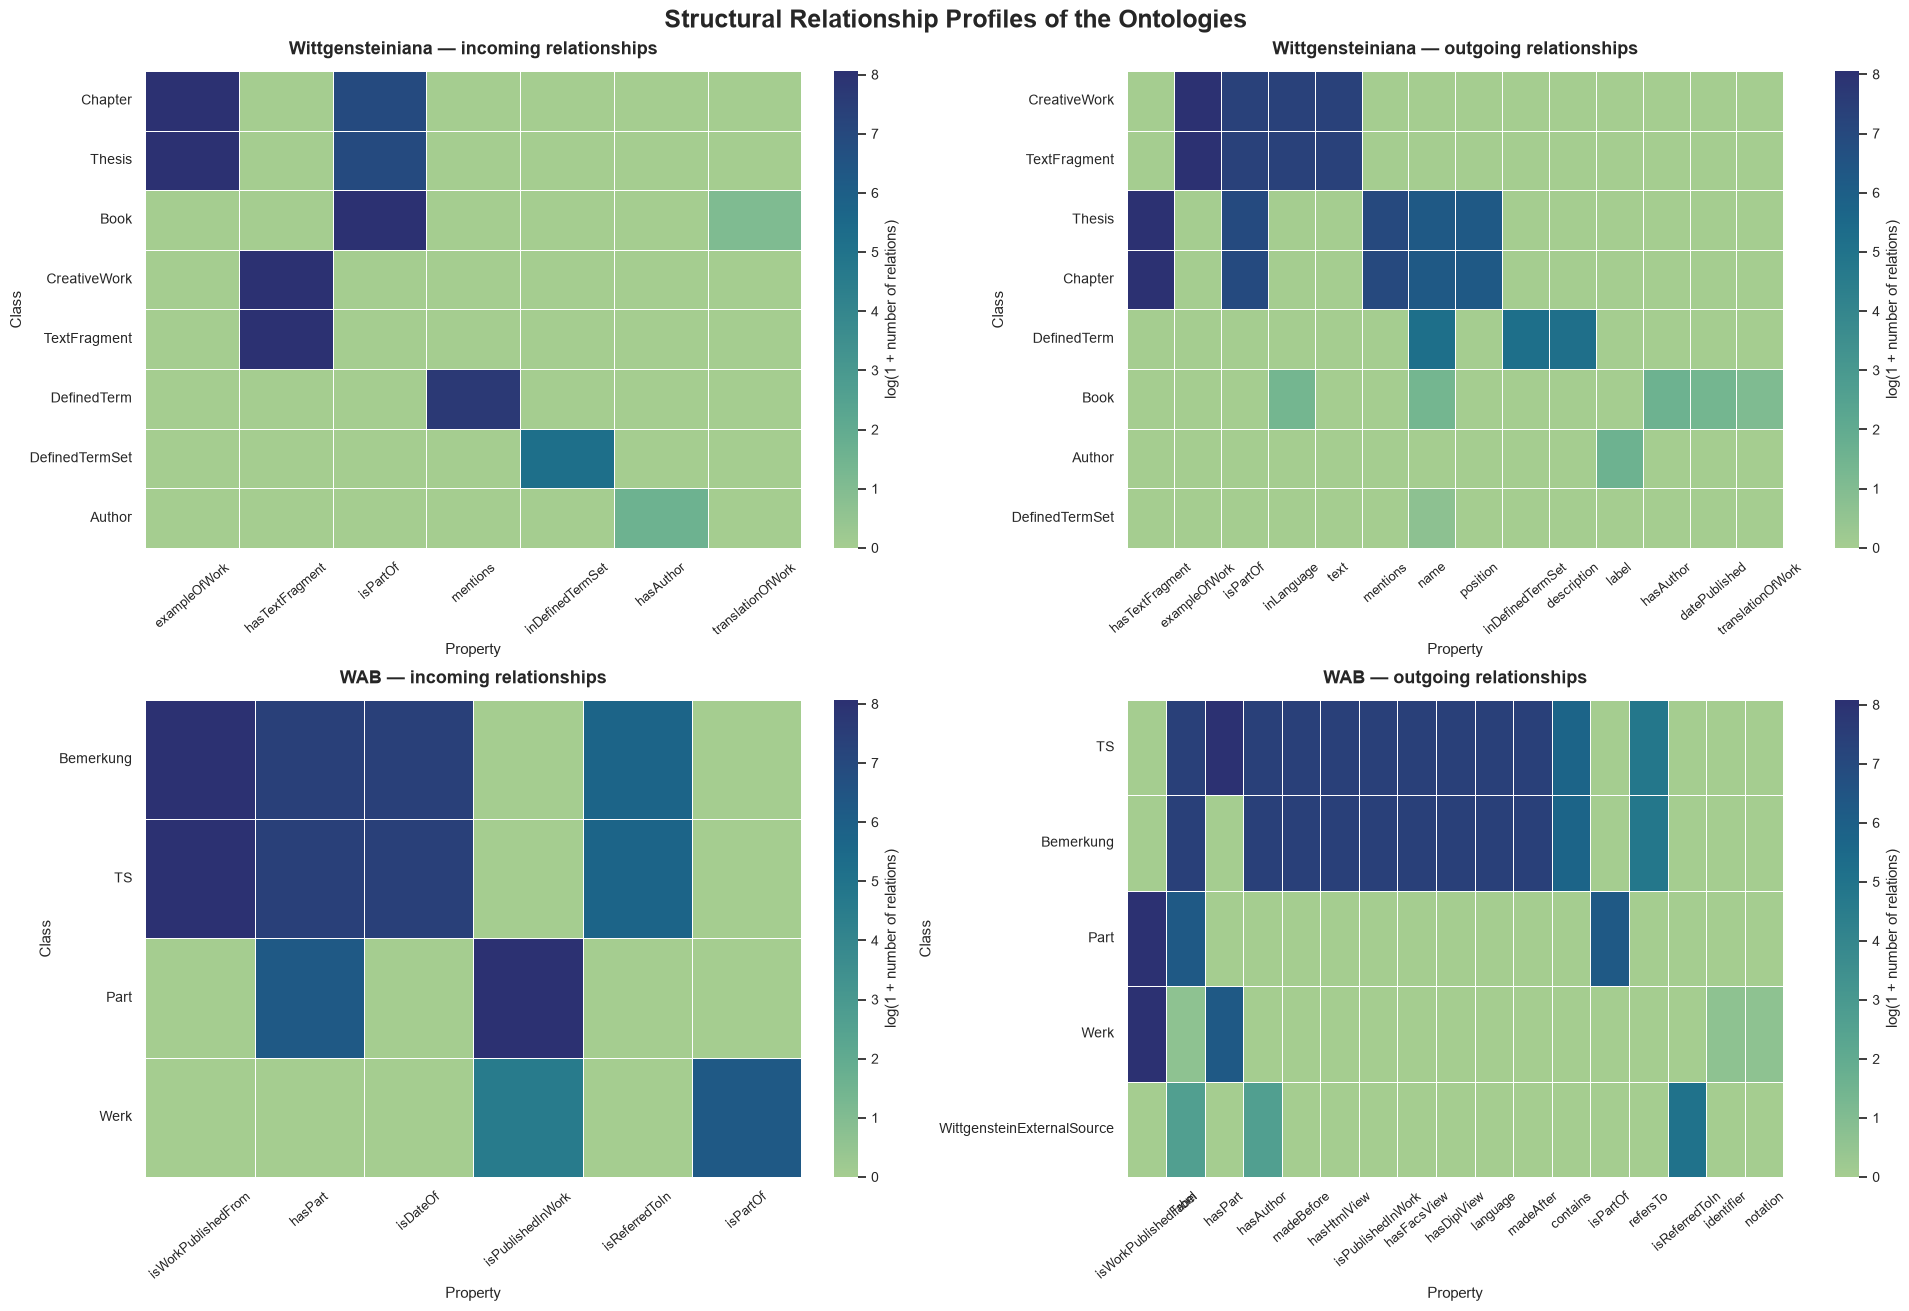

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

sns.set_theme(style="white", font_scale=0.9)

fig, axes = plt.subplots(
    2, 2,
    figsize=(19, 13),
    constrained_layout=True
)

configurations = [
    ("Wittgensteiniana", "Incoming", axes[0, 0]),
    ("Wittgensteiniana", "Outgoing", axes[0, 1]),
    ("WAB", "Incoming", axes[1, 0]),
    ("WAB", "Outgoing", axes[1, 1])
]

for ontology_name, direction, ax in configurations:

    data = class_structure_summary[
        (class_structure_summary["Ontology"] == ontology_name) &
        (class_structure_summary["Direction"] == direction)
    ]

    heatmap_data = data.pivot_table(
        index="Class",
        columns="Property",
        values="Number of relations",
        aggfunc="sum",
        fill_value=0
    )

    heatmap_data = heatmap_data.loc[
        heatmap_data.sum(axis=1).sort_values(
            ascending=False
        ).index
    ]

    heatmap_data = heatmap_data[
        heatmap_data.sum(axis=0).sort_values(
            ascending=False
        ).index
    ]

    sns.heatmap(
        np.log1p(heatmap_data),
        ax=ax,
        cmap="crest",
        linewidths=0.7,
        linecolor="white",
        annot=False,
        cbar_kws={
            "label": "log(1 + number of relations)"
        }
    )

    ax.set_title(
        f"{ontology_name} — {direction.lower()} relationships",
        fontsize=13,
        fontweight="bold",
        pad=12
    )

    ax.set_xlabel("Property")
    ax.set_ylabel("Class")

    ax.tick_params(axis="x", rotation=40, labelsize=9)
    ax.tick_params(axis="y", rotation=0, labelsize=10)

fig.suptitle(
    "Structural Relationship Profiles of the Ontologies",
    fontsize=18,
    fontweight="bold"
)

plt.show()

## Identification of candidate class correspondences

At this stage, potential correspondences between classes in Wittgensteiniana and WAB are identified based on their structural characteristics.

The comparison considers the distribution of incoming and outgoing relationships, the number of distinct properties, and the diversity of related resource types.

Since the ontologies use different property names and class structures, the analysis focuses on general structural characteristics rather than exact property matches.

The resulting similarity scores are exploratory indicators. They do not establish semantic equivalence and require further examination.

In [68]:
profile_rows = []

for ontology_name in ["Wittgensteiniana", "WAB"]:
    ontology_data = class_structure_summary[
        class_structure_summary["Ontology"] == ontology_name
    ]

    for class_name in ontology_data["Class"].unique():
        class_data = ontology_data[
            ontology_data["Class"] == class_name
        ]

        incoming = class_data[
            class_data["Direction"] == "Incoming"
        ]

        outgoing = class_data[
            class_data["Direction"] == "Outgoing"
        ]

        incoming_count = incoming["Number of relations"].sum()
        outgoing_count = outgoing["Number of relations"].sum()

        total_count = incoming_count + outgoing_count

        profile_rows.append({
            "Ontology": ontology_name,
            "Class": class_name,
            "Incoming share": (
                incoming_count / total_count
                if total_count else 0
            ),
            "Outgoing share": (
                outgoing_count / total_count
                if total_count else 0
            ),
            "Incoming properties": incoming["Property"].nunique(),
            "Outgoing properties": outgoing["Property"].nunique(),
            "Incoming related types": incoming["Related type"].nunique(),
            "Outgoing related types": outgoing["Related type"].nunique()
        })

class_profiles_df = pd.DataFrame(profile_rows)

display(class_profiles_df)

,Ontology,Class,Incoming share,Outgoing share,Incoming properties,Outgoing properties,Incoming related types,Outgoing related types
0,Wittgensteiniana,Author,0.500000,0.500000,1,1,1,1
1,Wittgensteiniana,Book,0.995293,0.004707,2,5,5,3
2,Wittgensteiniana,Chapter,0.397837,0.602163,2,5,4,7
3,Wittgensteiniana,CreativeWork,0.285714,0.714286,1,4,2,4
4,Wittgensteiniana,DefinedTerm,0.801904,0.198096,1,3,2,2
5,Wittgensteiniana,DefinedTermSet,0.994536,0.005464,1,1,1,1
6,Wittgensteiniana,TextFragment,0.285714,0.714286,1,4,2,4
7,Wittgensteiniana,Thesis,0.397837,0.602163,2,5,4,7
8,WAB,Bemerkung,0.309822,0.690178,4,11,6,6
9,WAB,Part,0.466243,0.533757,2,3,3,4


In [69]:
from sklearn.metrics.pairwise import cosine_similarity

witt_profiles = class_profiles_df[
    class_profiles_df["Ontology"] == "Wittgensteiniana"
].copy()

wab_profiles = class_profiles_df[
    class_profiles_df["Ontology"] == "WAB"
].copy()

feature_columns = [
    "Incoming share",
    "Outgoing share",
    "Incoming properties",
    "Outgoing properties",
    "Incoming related types",
    "Outgoing related types"
]

witt_matrix = witt_profiles[feature_columns].to_numpy(dtype=float)
wab_matrix = wab_profiles[feature_columns].to_numpy(dtype=float)

similarity_matrix = cosine_similarity(
    witt_matrix,
    wab_matrix
)

structural_similarity_df = pd.DataFrame(
    similarity_matrix,
    index=witt_profiles["Class"],
    columns=wab_profiles["Class"]
)

display(
    structural_similarity_df.round(3)
)

Class,Bemerkung,Part,TS,Werk,WittgensteinExternalSource
Class,,,,,
Author,0.895,0.950,0.891,0.924,0.693
Book,0.961,0.936,0.947,0.949,0.662
Chapter,0.920,0.986,0.946,0.967,0.880
CreativeWork,0.953,0.960,0.976,0.984,0.918
DefinedTerm,0.981,0.950,0.980,0.978,0.780
DefinedTermSet,0.845,0.899,0.840,0.856,0.615
TextFragment,0.953,0.960,0.976,0.984,0.918
Thesis,0.920,0.986,0.946,0.967,0.880


In [70]:
candidate_rows = []

for witt_class in structural_similarity_df.index:
    for wab_class in structural_similarity_df.columns:
        candidate_rows.append({
            "Wittgensteiniana class": witt_class,
            "WAB class": wab_class,
            "Structural similarity": structural_similarity_df.loc[
                witt_class, wab_class
            ]
        })

structural_candidates_df = pd.DataFrame(candidate_rows)

structural_candidates_df = (
    structural_candidates_df
    .sort_values(
        "Structural similarity",
        ascending=False
    )
    .reset_index(drop=True)
)

display(structural_candidates_df.head(20))

,Wittgensteiniana class,WAB class,Structural similarity
0,Thesis,Part,0.986416
1,Chapter,Part,0.986416
2,CreativeWork,Werk,0.984220
3,TextFragment,Werk,0.984220
4,DefinedTerm,Bemerkung,0.981028
5,DefinedTerm,TS,0.979716
6,DefinedTerm,Werk,0.978133
7,CreativeWork,TS,0.975961
8,TextFragment,TS,0.975961
9,Thesis,Werk,0.967083
